# Customer Segmentation Analysis Using K-Means Clustering

## 1. Importing Required Libraries

This project uses Python libraries for data manipulation,
numerical calculations, data visualisation and customer segmentation.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Program Files\Python314\python.exe -m pip install --upgrade pip


## 2. Loading the Dataset

In this section, we load the Online Retail dataset using pandas
and inspect the customer transaction records.

In [15]:
import sys
!{sys.executable} -m pip install openpyxl


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
df = pd.read_excel("dataset/Online_Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [17]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 3. Data Cleaning

Data cleaning is performed to handle missing values,
duplicate records and invalid transactions before analysis.

In [18]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check negative and zero quantities
print("\nQuantity <= 0:", (df['Quantity'] <= 0).sum())

# Check zero or negative unit prices
print("\nUnitPrice <= 0:", (df['UnitPrice'] <= 0).sum())

# Check cancelled orders
print("\nCancelled Orders:", df['InvoiceNo'].str.startswith('C').sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268

Quantity <= 0: 10624

UnitPrice <= 0: 2517

Cancelled Orders: 9288


### 3.1 Handling Missing Values and Duplicate Records

Missing CustomerID values are removed because customer
identification is essential for customer segmentation.

Duplicate transaction records are also removed to
avoid repeated records during analysis.

In [19]:
# Create a copy of the original dataset

df_clean = df.copy()

# Remove records with missing CustomerID
df_clean = df_clean.dropna(subset=['CustomerID'])

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

print("Shape after removing missing CustomerID and duplicates:")
print(df_clean.shape)

Shape after removing missing CustomerID and duplicates:
(401604, 8)


### 3.2 Removing Cancelled and Invalid Transactions

Cancelled orders, negative or zero quantities and
invalid unit prices are excluded from the analysis.

In [20]:
# Remove cancelled orders
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Keep only positive quantities
df_clean = df_clean[df_clean['Quantity'] > 0]

# Keep only positive unit prices
df_clean = df_clean[df_clean['UnitPrice'] > 0]

print("Shape after removing invalid transactions:")
print(df_clean.shape)

Shape after removing invalid transactions:
(392692, 8)


In [21]:
# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())

# Check duplicates
print("\nDuplicate Records:", df_clean.duplicated().sum())

# Check cleaned dataset
print("\nCleaned Dataset Shape:", df_clean.shape)

# Display first five rows
df_clean.head()

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicate Records: 0

Cleaned Dataset Shape: (392692, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [22]:
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

print(df_clean['CustomerID'].dtype)

int64


## 4. RFM Analysis

RFM analysis is used to understand customer purchasing
behaviour based on Recency, Frequency and Monetary value.

### 4.1 Calculating Total Purchase Amount

Total purchase amount is calculated by multiplying
Quantity by UnitPrice.

In [23]:
# Calculate total purchase amount

df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Display first five rows
df_clean[['CustomerID', 'InvoiceNo', 'Quantity',
          'UnitPrice', 'TotalAmount']].head()

,CustomerID,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,17850,536365,6,2.55,15.30
1,17850,536365,6,3.39,20.34
2,17850,536365,8,2.75,22.00
3,17850,536365,6,3.39,20.34
4,17850,536365,6,3.39,20.34


### 4.2 Calculating RFM Values

We calculate three important customer behaviour features:

1. Recency – Number of days since the last purchase.
2. Frequency – Total number of unique orders.
3. Monetary – Total amount spent by each customer.

In [24]:
# Set reference date
reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

# Display first five customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [25]:
print("RFM Dataset Shape:", rfm.shape)

print("\nRFM Statistics:")
print(rfm.describe())

RFM Dataset Shape: (4338, 3)

RFM Statistics:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [26]:
# Calculate descriptive statistics

average_purchase_value = df_clean['TotalAmount'].mean()

average_purchase_frequency = rfm['Frequency'].mean()

average_customer_value = rfm['Monetary'].mean()

print("Average Purchase Value:", round(average_purchase_value, 2))

print("Average Purchase Frequency:", round(average_purchase_frequency, 2))

print("Average Customer Lifetime Value:", round(average_customer_value, 2))

Average Purchase Value: 22.63
Average Purchase Frequency: 4.27
Average Customer Lifetime Value: 2048.69


In [27]:
# Calculate Average Order Value (AOV)

total_revenue = df_clean['TotalAmount'].sum()

total_orders = df_clean['InvoiceNo'].nunique()

average_order_value = total_revenue / total_orders

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 479.56


## 5. Feature Selection and Standardisation

We select Recency, Frequency and Monetary as the
three important behavioural features for customer segmentation.


In [28]:
# Select RFM features

rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]

# Display selected features
rfm_features.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [29]:
# Standardise RFM features

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

# Convert scaled data into DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

# Display scaled data
rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812


In [30]:
print("Mean of scaled features:")
print(rfm_scaled.mean().round(2))

print("\nStandard deviation of scaled features:")
print(rfm_scaled.std().round(2))

Mean of scaled features:
Recency      0.0
Frequency    0.0
Monetary     0.0
dtype: float64

Standard deviation of scaled features:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


## 6. Finding Optimal Number of Clusters

The Elbow Method is used to determine the optimal
number of clusters for K-Means clustering.

It calculates the inertia for different values of K.
The optimal K is estimated by identifying the elbow point
where the reduction in inertia starts slowing down.

In [32]:
# Calculate WCSS for different number of clusters

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS Values:", wcss)

WCSS Values: [13014.000000000002, 9014.566279572977, 5441.32358682966, 4096.30021066225, 3119.78985980015, 2473.7933635647605, 2023.586627223549, 1717.0110430839181, 1468.787102184297, 1281.0480511013268]


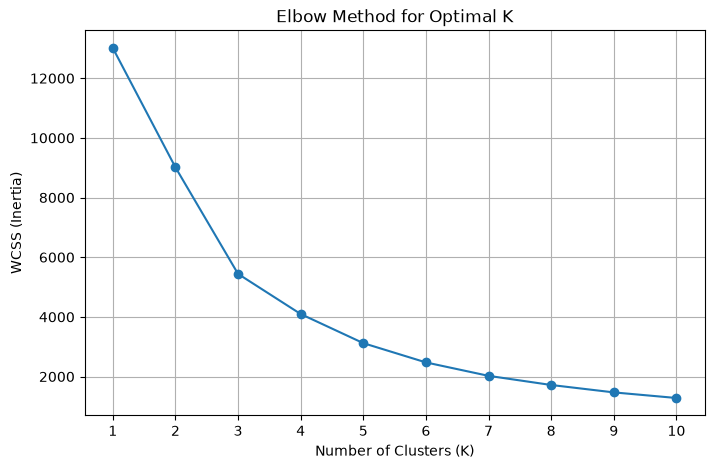

In [33]:
# Plot Elbow Method

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

## 7. Applying K-Means Clustering

K-Means is an unsupervised machine learning algorithm
used to divide customers into different groups based
on similar purchasing behaviour.

Based on the Elbow Method, we select 3 clusters.

In [34]:
# Apply K-Means clustering

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means clustering completed successfully!")

K-Means clustering completed successfully!


In [35]:
# Display customer segments

print(rfm.head(10))

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346           326          1  77183.60        0
12347             2          7   4310.00        1
12348            75          4   1797.24        1
12349            19          1   1757.55        1
12350           310          1    334.40        0
12352            36          8   2506.04        1
12353           204          1     89.00        0
12354           232          1   1079.40        0
12355           214          1    459.40        0
12356            23          3   2811.43        1


In [37]:
# Display customer segments

# Count customers in each cluster

cluster_counts = rfm['Cluster'].value_counts().sort_index()

print("Number of Customers in Each Cluster:")
print(cluster_counts)

Number of Customers in Each Cluster:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


In [38]:
# Calculate mean RFM values for each cluster

cluster_profile = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2)

print("Customer Segment Profiles:")
print(cluster_profile)

Customer Segment Profiles:
         Recency  Frequency  Monetary
Cluster                              
0         247.11       1.58    629.66
1          41.45       4.67   1849.67
2           6.04      66.42  85826.08



## 8. Cluster Visualisation

Visualisation helps us understand the distribution
of customers across different clusters.

### 8.1 Recency vs Monetary

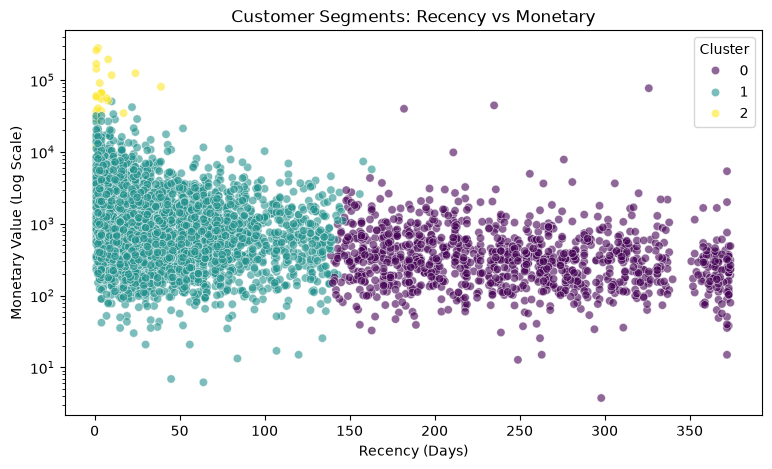

In [39]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    alpha=0.6
)

plt.yscale('log')

plt.title('Customer Segments: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value (Log Scale)')
plt.legend(title='Cluster')

plt.show()

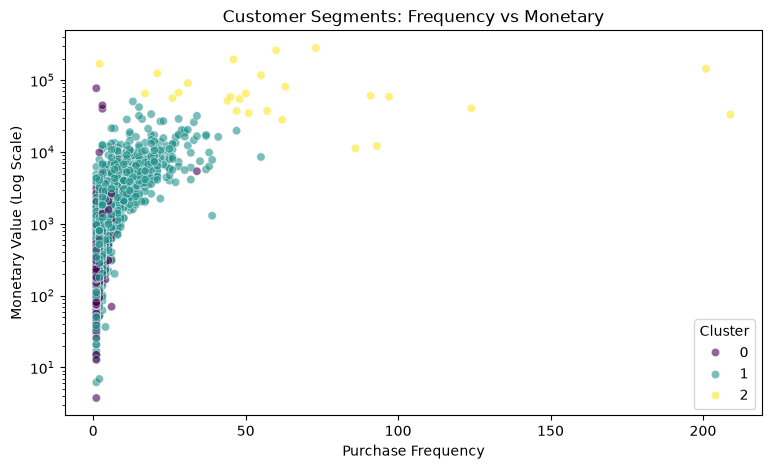

In [40]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    alpha=0.6
)

plt.yscale('log')

plt.title('Customer Segments: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Monetary Value (Log Scale)')
plt.legend(title='Cluster')

plt.show()

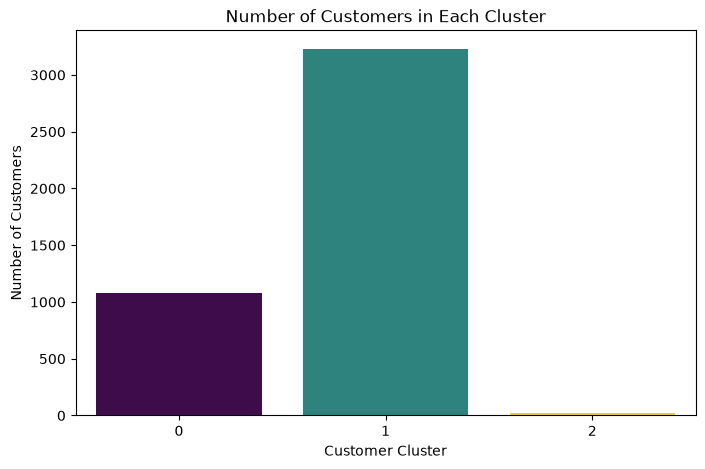

In [41]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

## 9. Customer Segment Profiling

In this section, we analyse each customer segment
using average RFM values and customer distribution.

This helps identify different customer purchasing behaviours.

In [43]:
# Calculate customer count for each cluster

cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
})

# Rename columns
cluster_profile.rename(
    columns={'Cluster': 'Customer_Count'},
    inplace=True
)

# Calculate percentage of customers
cluster_profile['Percentage'] = (
    cluster_profile['Customer_Count'] / len(rfm) * 100
).round(2)

# Round average values
cluster_profile = cluster_profile.round(2)

print("Final Customer Segment Profile:")
print(cluster_profile)

Final Customer Segment Profile:
         Recency  Frequency  Monetary  Customer_Count  Percentage
Cluster                                                          
0         247.11       1.58    629.66            1082       24.94
1          41.45       4.67   1849.67            3230       74.46
2           6.04      66.42  85826.08              26        0.60


In [44]:
# Check Cluster 2 customers

print("Cluster 2 Customer Details:")

print(
    rfm[rfm['Cluster'] == 2]
    .sort_values('Monetary', ascending=False)
    .head(10)
)

Cluster 2 Customer Details:
            Recency  Frequency   Monetary  Cluster
CustomerID                                        
14646             2         73  280206.02        2
18102             1         60  259657.30        2
17450             8         46  194390.79        2
16446             1          2  168472.50        2
14911             1        201  143711.17        2
12415            24         21  124914.53        2
14156            10         55  117210.08        2
17511             3         31   91062.38        2
16029            39         63   80850.84        2
16684             4         28   66653.56        2


In [45]:
# Calculate final customer segment profile

cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
})

cluster_profile.rename(
    columns={'Cluster': 'Customer_Count'},
    inplace=True
)

cluster_profile['Percentage'] = (
    cluster_profile['Customer_Count'] / len(rfm) * 100
).round(2)

print(cluster_profile.round(2))

         Recency  Frequency  Monetary  Customer_Count  Percentage
Cluster                                                          
0         247.11       1.58    629.66            1082       24.94
1          41.45       4.67   1849.67            3230       74.46
2           6.04      66.42  85826.08              26        0.60


## 10. Business Insights and Marketing Recommendations

Based on the K-Means clustering results, three customer
segments were identified.

### Cluster 0 – At-Risk Customers
- Customers have not purchased recently.
- They have low purchase frequency and spending.
- Recommendation: Send personalised offers and
  re-engagement emails.

### Cluster 1 – Regular Customers
- Customers purchase more frequently than Cluster 0.
- They show moderate spending behaviour.
- Recommendation: Provide loyalty points, discounts
  and repeat-purchase offers.

### Cluster 2 – High-Value Customers
- Customers show very high monetary value.
- They have relatively recent purchase activity.
- Recommendation: Offer VIP rewards, exclusive deals
  and personalised services.

### Overall Business Insight
Customer segmentation helps businesses understand
different purchasing behaviours and develop targeted
marketing strategies to improve customer retention
and sales performance.

## 11. Conclusion

Customer Segmentation Analysis was performed using the Online Retail dataset and K-Means clustering algorithm.

The RFM technique was used to analyse customer purchasing behaviour based on Recency, Frequency and Monetary value.

The Elbow Method was applied to identify the optimal number of clusters, and three customer segments were created.

The analysis identified three major customer groups:

- **Cluster 0 – At-Risk Customers:** Customers with low purchase frequency and spending who require re-engagement strategies.
- **Cluster 1 – Regular Customers:** Customers with moderate purchasing activity who can be encouraged through loyalty programmes.
- **Cluster 2 – High-Value Customers:** Customers with exceptionally high spending who can be retained through exclusive rewards and personalised offers.

The visualisations helped understand the differences between customer segments.

Overall, this project demonstrates how machine learning and customer data analysis can help businesses understand purchasing behaviour and develop effective marketing strategies.

In [47]:
%whos

Variable                     Type              Data/Info
--------------------------------------------------------
KMeans                       ABCMeta           <class 'sklearn.cluster._kmeans.KMeans'>
StandardScaler               type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
average_customer_value       float64           2048.688080682342
average_order_value          float64           479.56016047917126
average_purchase_frequency   float64           4.272014753342554
average_purchase_value       float64           22.631499735161402
cluster_counts               Series            Shape: (3,)
cluster_profile              DataFrame         Shape: (3, 5)
df                           DataFrame         Shape: (541909, 8)
df_clean                     DataFrame         Shape: (392692, 9)
k                            int               10
kmeans                       KMeans            KMeans(n_clusters=3, n_init=10, random_state=42)
np                           module

In [48]:
print("Customer Count in Each Cluster:")
print(rfm['Cluster'].value_counts().sort_index())

print("\nCluster Percentage:")
print((rfm['Cluster'].value_counts(normalize=True).sort_index() * 100).round(2))

Customer Count in Each Cluster:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64

Cluster Percentage:
Cluster
0    24.94
1    74.46
2     0.60
Name: proportion, dtype: float64
